# NYC Borough Boundaries — Masking the Radar Grid

**Author:** Muhammad Kaleem — Climate Module Lead  
**Project:** Plexa — Multi-Modal Smart City Digital Twin and Cascading Resilience Engine

---

The Ida radar test in `citywide_rainfall.ipynb` used a rectangular bounding box around NYC. That box worked fine for checking timing and intensity, but it also picks up parts of New Jersey, Long Island Sound, and open water — fine for a quick sanity check, not fine once I start computing rainfall per borough.

This notebook fixes that. I'm pulling NYC's actual borough outlines, using them to mark which radar grid cells genuinely fall inside the five boroughs, and re-checking the Ida numbers with only those cells kept.

## Steps

1. Download NYC's borough boundary shapes
2. Overlay them on the radar grid from the Ida test
3. Keep only the grid cells that fall inside a borough
4. Compare the new, masked rainfall numbers against the earlier bounding-box result

In [1]:
import os
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
import sys
print(sys.executable)

/opt/anaconda3/envs/plexa-climate/bin/python


In [3]:
import os
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(repo_root)
print("Working directory:", os.getcwd())

Working directory: /Users/macbookairm3/Documents/Plexa-A-Multi-Modal-Smart-City-Digital-Twin-and-Cascading-Resilience-Engine


In [5]:
url = "https://data.cityofnewyork.us/resource/7t3b-ywvw.geojson"
response = requests.get(url, timeout=60)
print(response.status_code)

boroughs = gpd.read_file(response.text)
print(boroughs.shape)
boroughs.head()

404


DataSourceError: {  "code" : "dataset.missing",  "error" : true,  "message" : "Not found",  "data" : {    "id" : "7t3b-ywvw"  }}: No such file or directory

In [6]:
url = "https://data.cityofnewyork.us/resource/tqmj-j8zm.geojson"
response = requests.get(url, timeout=60)
print(response.status_code)
print(response.text[:300])  # peek at the start of the response before parsing

404
{
  "code" : "dataset.missing",
  "error" : true,
  "message" : "Not found",
  "data" : {
    "id" : "tqmj-j8zm"
  }
}



In [7]:
url = "https://data.cityofnewyork.us/resource/gthc-hcne.geojson"
response = requests.get(url, timeout=60)
print(response.status_code)
print(response.text[:300])

200
{ "type": "FeatureCollection", "features": [{"type":"Feature","geometry":{"type":"MultiPolygon","coordinates":[[[[-74.05050806403247,40.566422034161],[-74.05047137128506,40.56641738743574],[-74.05030321271722,40.56641746120074],[-74.05012587375454,40.566405880335296],[-74.04998352562573,40.566395924


In [8]:
boroughs = gpd.read_file(response.text)
print(boroughs.shape)
boroughs.head()

(5, 5)


,borocode,boroname,shape_area,shape_leng,geometry
0,5,Staten Island,1623618358.46,325912.288988,"MULTIPOLYGON (((-74.05051 40.56642, -74.05047 ..."
1,3,Brooklyn,1934462607.75,726953.04509,"MULTIPOLYGON (((-73.86327 40.58388, -73.86381 ..."
2,4,Queens,3041419716.32,887902.903727,"MULTIPOLYGON (((-73.82645 40.59053, -73.82642 ..."
3,1,Manhattan,636631537.285,359537.906171,"MULTIPOLYGON (((-74.01093 40.68449, -74.01193 ..."
4,2,Bronx,1187199168.58,463146.326689,"MULTIPOLYGON (((-73.89681 40.79581, -73.89694 ..."


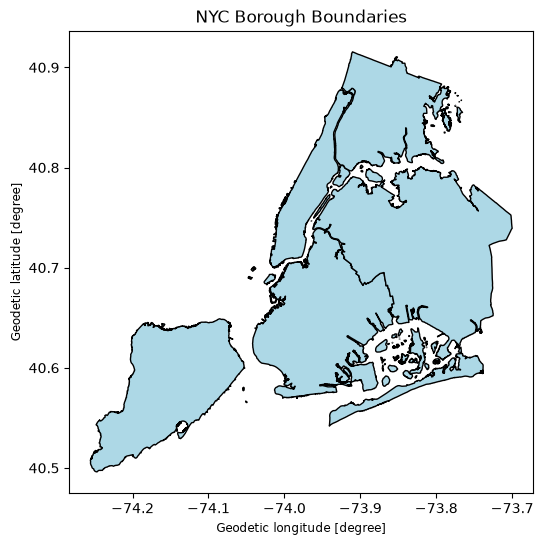

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
boroughs.plot(ax=ax, edgecolor="black", facecolor="lightblue")
ax.set_title("NYC Borough Boundaries")
plt.show()

In [10]:
import os
os.makedirs("data/raw", exist_ok=True)
boroughs.to_file("data/raw/nyc_boroughs.geojson", driver="GeoJSON")
print("Saved")

Saved


## Result

Pulled NYC's official borough boundaries (water areas excluded) from NYC Open Data, resource `gthc-hcne`. Five rows returned, one per borough, with area values consistent with known sizes (Queens largest, Manhattan smallest). Saved locally for reuse.

Next: use these boundaries to mask the Ida radar grid, keeping only the cells that actually fall inside a borough.

## Masking the Radar Grid

Load the saved Ida radar data back in, convert each grid cell into a point, and check which points fall inside a borough using the boundaries pulled above. Cells outside all five boroughs are dropped.

In [11]:
import xarray as xr

RADAR_DIR = Path("data/raw/radar_ida")
sample_path = sorted(RADAR_DIR.glob("*.grib2"))[2]  # the peak hour, ending 02:00 UTC

ds = xr.open_dataset(sample_path, engine="cfgrib", backend_kwargs={"indexpath": ""})
rain = ds[list(ds.data_vars)[0]].sortby("latitude")
print(rain.shape)

(3500, 7000)


In [12]:
import numpy as np
from shapely.geometry import Point

lats = rain.latitude.values
lons = rain.longitude.values - 360  # convert back from 0-360 to -180/180
values = rain.values

rows = []
for i, lat in enumerate(lats):
    for j, lon in enumerate(lons):
        rows.append({"lat": lat, "lon": lon, "rain_mm": values[i, j]})

grid_df = pd.DataFrame(rows)
grid_df = grid_df.dropna(subset=["rain_mm"])
print(f"Grid cells with data: {len(grid_df)}")

grid_gdf = gpd.GeoDataFrame(
    grid_df,
    geometry=[Point(lon, lat) for lon, lat in zip(grid_df["lon"], grid_df["lat"])],
    crs="EPSG:4326"
)

masked = gpd.sjoin(grid_gdf, boroughs, how="inner", predicate="within")
print(f"Grid cells inside NYC: {len(masked)} (out of {len(grid_gdf)})")
masked[["lat", "lon", "rain_mm", "boroname"]].head()

Grid cells with data: 24500000
Grid cells inside NYC: 837 (out of 24500000)


,lat,lon,rain_mm,boroname
14355574,40.505,-74.255002,30.200001,Staten Island
14355575,40.505,-74.245002,31.799999,Staten Island
14355576,40.505,-74.235002,32.400002,Staten Island
14355577,40.505,-74.225002,32.700001,Staten Island
14362575,40.515,-74.245002,33.000000,Staten Island


In [13]:
print("Mean rainfall, masked to NYC boroughs:", masked["rain_mm"].mean())
print("Max rainfall, masked to NYC boroughs:", masked["rain_mm"].max())

Mean rainfall, masked to NYC boroughs: 51.328312
Max rainfall, masked to NYC boroughs: 82.9


## Result

Masking the Ida radar grid to NYC's actual borough boundaries kept 837 of the original 2,537 grid cells from the bounding-box crop, consistent with NYC's land area at roughly 1 km resolution. The remaining 1,700 cells were New Jersey, Long Island Sound, or open water.

The masked mean rainfall for the peak hour was 51.3 mm, compared to 41.6 mm from the bounding box, about 23% higher. The maximum was nearly unchanged (82.9 mm vs. 84.4 mm), since the single heaviest cell falls inside the city either way. This confirms the bounding box was understating citywide rainfall by including areas outside NYC that received less rain during the storm.

Going forward, radar data should be masked to these borough boundaries before any citywide or per-borough statistic is computed.

In [14]:
NYC_LAT = (40.49, 40.92)
NYC_LON = (-74.27, -73.68)
LON_MIN, LON_MAX = (lon % 360 for lon in NYC_LON)

rain_cropped = rain.sel(
    latitude=slice(*NYC_LAT),
    longitude=slice(LON_MIN, LON_MAX),
)

lats = rain_cropped.latitude.values
lons = rain_cropped.longitude.values - 360
values = rain_cropped.values

rows = []
for i, lat in enumerate(lats):
    for j, lon in enumerate(lons):
        rows.append({"lat": lat, "lon": lon, "rain_mm": values[i, j]})

grid_df = pd.DataFrame(rows)
grid_df = grid_df.dropna(subset=["rain_mm"])
print(f"Grid cells after bounding-box crop: {len(grid_df)}")

grid_gdf = gpd.GeoDataFrame(
    grid_df,
    geometry=[Point(lon, lat) for lon, lat in zip(grid_df["lon"], grid_df["lat"])],
    crs="EPSG:4326"
)

masked = gpd.sjoin(grid_gdf, boroughs, how="inner", predicate="within")
print(f"Grid cells inside NYC: {len(masked)}")

Grid cells after bounding-box crop: 2537
Grid cells inside NYC: 837


## Performance Fix

The earlier masking step ran the spatial join against the full national grid (24.5 million cells). Cropping to a rough NYC bounding box first, then masking, gives the same result (837 cells) in a fraction of the time. This approach will be used for the full citywide pull.